# 1 · Flying hours you can't predict

Sample a year of weekly flight hours, compare the closed-form spread with simulation, and see how long a 600 FH interval lasts. See [Lesson 1](../docs/lessons/01-flying-hours-you-cant-predict.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fracsched.problem import small_problem
from fracsched.utilization_model import default_model

rng = np.random.default_rng(1)
problem = small_problem(0)  # AVR-04's small instance on the flight-hour clock
model = default_model()

closed form: mean 800 FH, sd 186 FH
simulated (capped): mean 797 FH, sd 184 FH


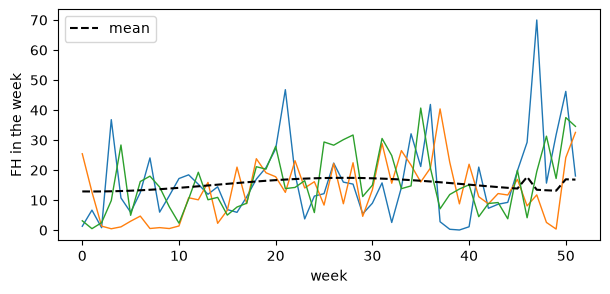

In [2]:
from fracsched.utilization_model import annual_mean, annual_sd, weekly_mean, weeks_to_reach

u, state = model.sample(rng, 4000, 10, 52)
years = u.sum(axis=-1).ravel()
exact = default_model(capped=False)
print(f"closed form: mean {annual_mean(exact):.0f} FH, sd {annual_sd(exact):.0f} FH")
print(f"simulated (capped): mean {years.mean():.0f} FH, sd {years.std():.0f} FH")
fig, ax = plt.subplots(figsize=(7, 3))
for a in range(3):
    ax.plot(u[0, a], lw=1)
ax.plot(weekly_mean(model), "k--", label="mean")
ax.set_xlabel("week")
ax.set_ylabel("FH in the week")
ax.legend();

In [3]:
long, _ = model.sample(rng, 2000, 10, 104)
weeks = weeks_to_reach(long, 600.0).ravel() + 1
print("weeks at mean use:", 600 / model.mean_weekly_fh)
print("P10, median, P90:", np.quantile(weeks, [0.1, 0.5, 0.9]))

weeks at mean use: 39.0
P10, median, P90: [29. 39. 57.]
